# TFM — Visualización de señales EEG para el documento

Genera dos figuras para incluir en la Metodología del TFM:

1. **Señal cruda + hipnograma** (para la sección "Conjunto de datos") —
   ilustra cómo son los datos antes de cualquier procesamiento.
2. **Señal antes vs. después del filtrado** (para la sección
   "Preprocesamiento") — justifica visualmente el filtro paso banda 0.5-30 Hz.

**Antes de ejecutar:** ajusta `DATA_DIR` a la carpeta donde tengas al menos
un par PSG/Hypnogram descargado (sirve tanto tu carpeta `datos` de
Sleep-EDF-20 como `datos_completos`).

In [8]:
import os
import glob
import mne
import numpy as np
import matplotlib.pyplot as plt

mne.set_log_level("WARNING")

TFM_DIR = os.path.expanduser("~/Desktop/TFM")
DATA_DIR = os.path.expanduser("~/Desktop/TFM/datos")  # ajusta si hace falta
IMAGES_DIR = os.path.join(TFM_DIR, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

CHANNELS = ["EEG Fpz-Cz", "EEG Pz-Oz"]

# Busca el primer par PSG/Hypnogram disponible como ejemplo
psg_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*-PSG.edf"), recursive=True))
psg_path = psg_files[2]  # o prueba con otro índice: 5, 10, etc.
prefix = os.path.basename(psg_path)[:6]
hyp_path = glob.glob(os.path.join(os.path.dirname(psg_path), prefix + "*-Hypnogram.edf"))[0]

print("Usando como ejemplo:")
print(" PSG:      ", os.path.basename(psg_path))
print(" Hypnogram:", os.path.basename(hyp_path))

Usando como ejemplo:
 PSG:       SC4011E0-PSG.edf
 Hypnogram: SC4011EH-Hypnogram.edf


## 1. Carga de la señal cruda (sin filtrar)

In [9]:
raw = mne.io.read_raw_edf(psg_path, preload=True)
annot = mne.read_annotations(hyp_path)
raw.set_annotations(annot, emit_warning=False)

sfreq = raw.info["sfreq"]
print("Frecuencia de muestreo:", sfreq, "Hz")
print("Canales disponibles:", raw.ch_names)

C:\Users\alber\AppData\Local\Temp\ipykernel_5020\719571304.py:1: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_5020\719571304.py:1: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_5020\719571304.py:1: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path, preload=True)


Frecuencia de muestreo: 100.0 Hz
Canales disponibles: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']


## 2. Figura 1 — Señal cruda (ambos canales) + hipnograma de la noche

Muestra los dos canales EEG a lo largo de toda la noche, junto con el
hipnograma correspondiente, para ilustrar el tipo de dato con el que se
trabaja (para la sección "Conjunto de datos").

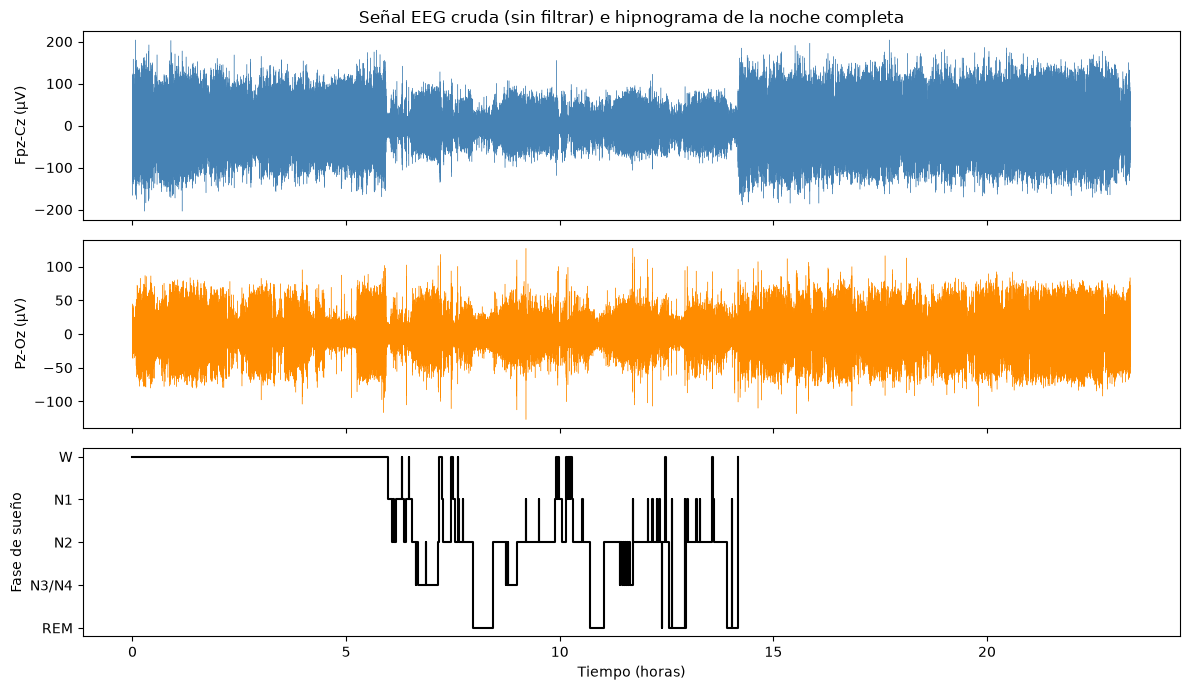

In [10]:
data_fpzcz, times = raw["EEG Fpz-Cz", :]
data_pzoz, _ = raw["EEG Pz-Oz", :]
data_fpzcz = data_fpzcz[0] * 1e6  # V -> uV
data_pzoz = data_pzoz[0] * 1e6

stage_map = {
    "Sleep stage W": 0, "Sleep stage 1": 1, "Sleep stage 2": 2,
    "Sleep stage 3": 3, "Sleep stage 4": 3, "Sleep stage R": 4,
}
onsets_h, stages_h = [], []
for ann in raw.annotations:
    if ann["description"] in stage_map:
        onsets_h.append(ann["onset"] / 3600)
        stages_h.append(stage_map[ann["description"]])

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

axes[0].plot(times / 3600, data_fpzcz, linewidth=0.3, color="steelblue")
axes[0].set_ylabel("Fpz-Cz (µV)")
axes[0].set_title("Señal EEG cruda (sin filtrar) e hipnograma de la noche completa")

axes[1].plot(times / 3600, data_pzoz, linewidth=0.3, color="darkorange")
axes[1].set_ylabel("Pz-Oz (µV)")

axes[2].step(onsets_h, stages_h, where="post", color="black")
axes[2].set_yticks([0, 1, 2, 3, 4])
axes[2].set_yticklabels(["W", "N1", "N2", "N3/N4", "REM"])
axes[2].invert_yaxis()
axes[2].set_ylabel("Fase de sueño")
axes[2].set_xlabel("Tiempo (horas)")

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "senal_cruda_hipnograma.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
## MEJORADA ABAJO

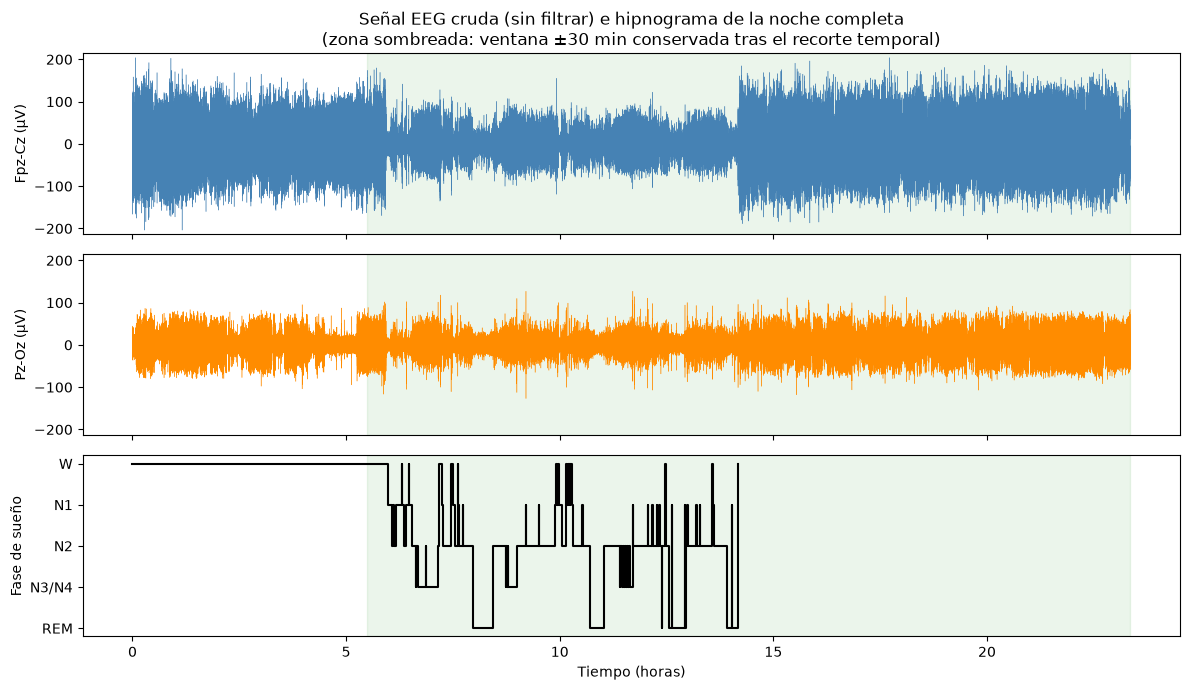

In [11]:
data_fpzcz, times = raw["EEG Fpz-Cz", :]
data_pzoz, _ = raw["EEG Pz-Oz", :]
data_fpzcz = data_fpzcz[0] * 1e6
data_pzoz = data_pzoz[0] * 1e6

stage_map = {
    "Sleep stage W": 0, "Sleep stage 1": 1, "Sleep stage 2": 2,
    "Sleep stage 3": 3, "Sleep stage 4": 3, "Sleep stage R": 4,
}
onsets_h, stages_h = [], []
for ann in raw.annotations:
    if ann["description"] in stage_map:
        onsets_h.append(ann["onset"] / 3600)
        stages_h.append(stage_map[ann["description"]])

# --- Misma lógica EXACTA que load_subject() en el pipeline real ---
sleep_onset = [a["onset"] for a in raw.annotations if a["description"] != "Sleep stage W"]
crop_start_sec = max(raw.times[0], min(sleep_onset) - 30 * 60)
crop_end_sec = min(raw.times[-1], max(sleep_onset) + 30 * 60)

t_crop_start = crop_start_sec / 3600
t_crop_end = crop_end_sec / 3600
# --------------------------------------------------------------

y_max = max(np.abs(data_fpzcz).max(), np.abs(data_pzoz).max()) * 1.05
y_lim = (-y_max, y_max)

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

for ax, data, ch_name, color in [
    (axes[0], data_fpzcz, "Fpz-Cz", "steelblue"),
    (axes[1], data_pzoz, "Pz-Oz", "darkorange"),
]:
    ax.plot(times / 3600, data, linewidth=0.3, color=color)
    ax.axvspan(t_crop_start, t_crop_end, color="green", alpha=0.08)
    ax.set_ylabel(f"{ch_name} (µV)")
    ax.set_ylim(y_lim)

axes[0].set_title("Señal EEG cruda (sin filtrar) e hipnograma de la noche completa\n(zona sombreada: ventana ±30 min conservada tras el recorte temporal)")

axes[2].step(onsets_h, stages_h, where="post", color="black")
axes[2].axvspan(t_crop_start, t_crop_end, color="green", alpha=0.08)
axes[2].set_yticks([0, 1, 2, 3, 4])
axes[2].set_yticklabels(["W", "N1", "N2", "N3/N4", "REM"])
axes[2].invert_yaxis()
axes[2].set_ylabel("Fase de sueño")
axes[2].set_xlabel("Tiempo (horas)")

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "senal_cruda_hipnograma.png"), dpi=150, bbox_inches="tight")
plt.show()

In [7]:
print("Último evento de sueño (h):", max(sleep_onset) / 3600)
print("Fin real de la grabación (h):", raw.times[-1] / 3600)

Último evento de sueño (h): 22.083333333333332
Fin real de la grabación (h): 22.083330555555555


## 3. Figura 2 — Señal antes vs. después del filtrado (0.5-30 Hz)

Compara un fragmento corto (30s, una época) de la señal cruda frente a la
misma señal tras aplicar el filtro paso banda, para justificar visualmente
la eliminación de ruido de baja y alta frecuencia (para la sección
"Preprocesamiento").

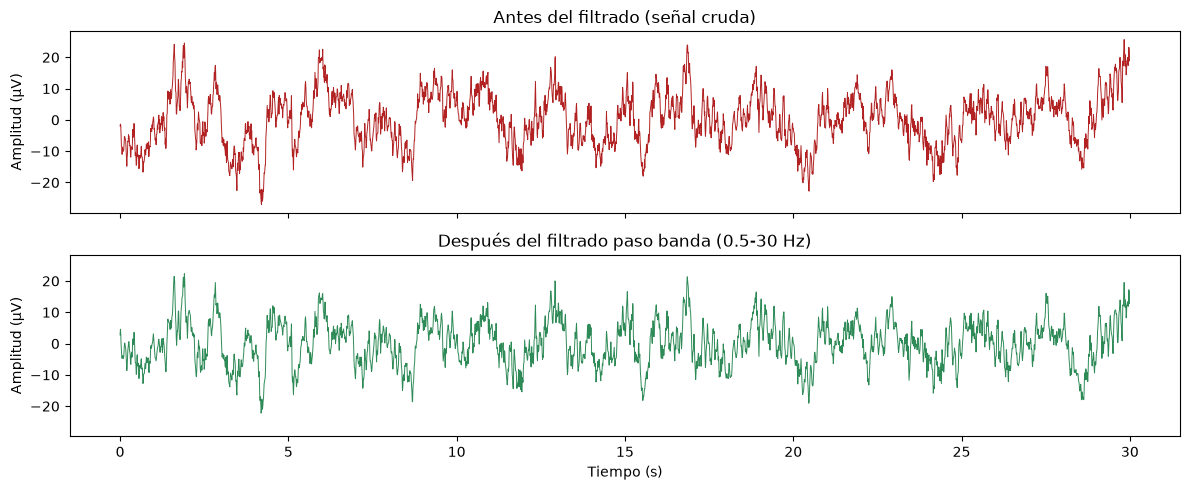

In [12]:
# Copia para filtrar, dejando intacta la señal cruda ya cargada
raw_filtered = raw.copy().filter(l_freq=0.5, h_freq=30.0, picks=CHANNELS)

data_filt, _ = raw_filtered["EEG Fpz-Cz", :]
data_filt = data_filt[0] * 1e6

# Ventana de 30s justo al inicio del periodo de sueño real (mismo criterio que en preprocesamiento)
sleep_onsets = [a["onset"] for a in annot if a["description"] != "Sleep stage W"]
t_start = sleep_onsets[0] if sleep_onsets else 60.0
n_samples_30s = int(30 * sfreq)
i_start = int(t_start * sfreq)
i_end = i_start + n_samples_30s

t_window = times[i_start:i_end] - times[i_start]

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, sharey=True)

axes[0].plot(t_window, data_fpzcz[i_start:i_end], linewidth=0.7, color="firebrick")
axes[0].set_title("Antes del filtrado (señal cruda)")
axes[0].set_ylabel("Amplitud (µV)")

axes[1].plot(t_window, data_filt[i_start:i_end], linewidth=0.7, color="seagreen")
axes[1].set_title("Después del filtrado paso banda (0.5-30 Hz)")
axes[1].set_ylabel("Amplitud (µV)")
axes[1].set_xlabel("Tiempo (s)")

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "senal_antes_despues_filtrado.png"), dpi=150, bbox_inches="tight")
plt.show()

## Próximos pasos

- `senal_cruda_hipnograma.png` → incluir en la sección **"Conjunto de
  datos"** (§5.2), como figura ilustrativa del tipo de dato.
- `senal_antes_despues_filtrado.png` → incluir en la sección
  **"Preprocesamiento"** (§5.4), justo después de describir el paso de
  filtrado, para justificar visualmente su efecto.

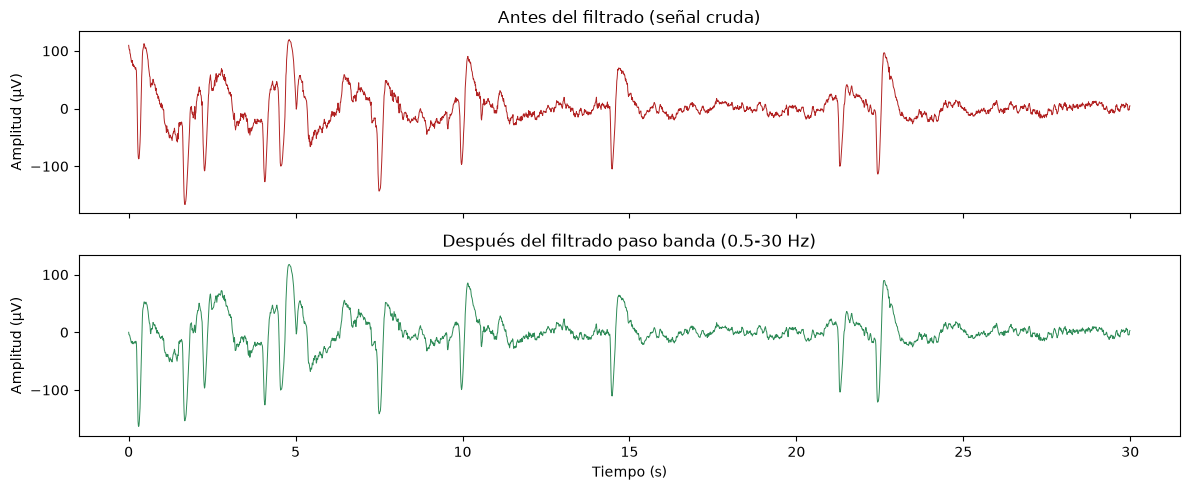

In [13]:
# En vez de la ventana al inicio del sueño, usamos los primeros 30s de la grabación
i_start = 0
n_samples_30s = int(30 * sfreq)
i_end = i_start + n_samples_30s

t_window = times[i_start:i_end] - times[i_start]

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, sharey=True)

axes[0].plot(t_window, data_fpzcz[i_start:i_end], linewidth=0.7, color="firebrick")
axes[0].set_title("Antes del filtrado (señal cruda)")
axes[0].set_ylabel("Amplitud (µV)")

axes[1].plot(t_window, data_filt[i_start:i_end], linewidth=0.7, color="seagreen")
axes[1].set_title("Después del filtrado paso banda (0.5-30 Hz)")
axes[1].set_ylabel("Amplitud (µV)")
axes[1].set_xlabel("Tiempo (s)")

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "senal_antes_despues_filtrado.png"), dpi=150, bbox_inches="tight")
plt.show()

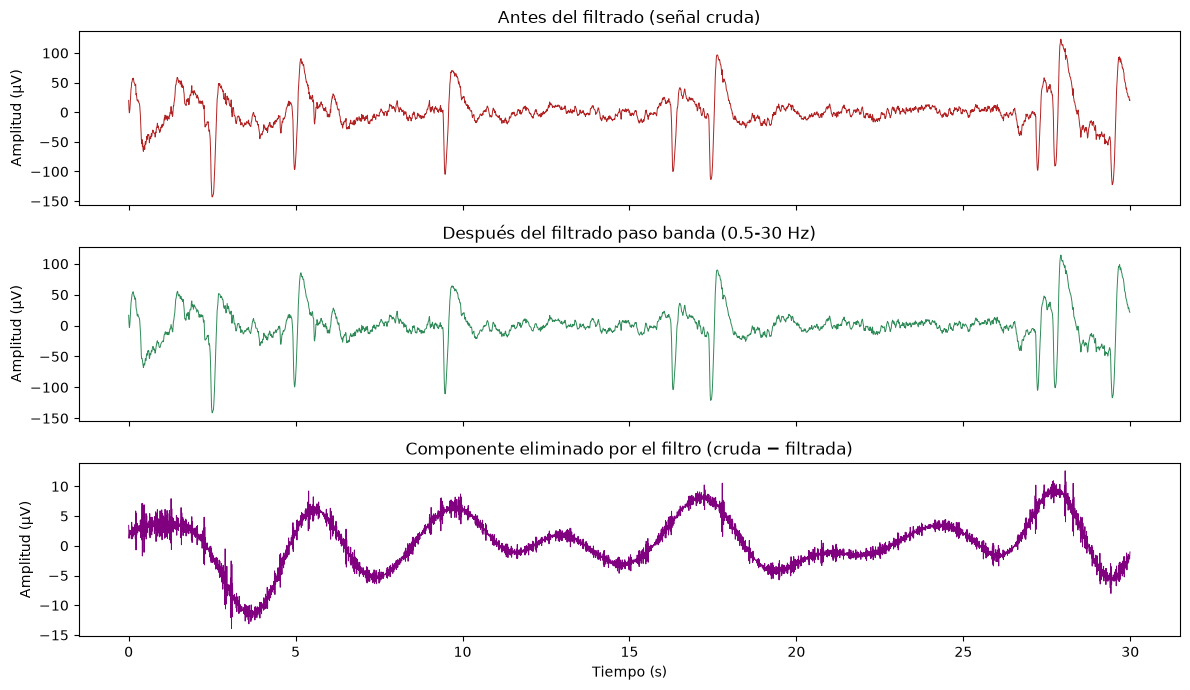

In [15]:
i_start = int(5 * sfreq)  # empieza en el segundo 5, no en el 0
n_samples_30s = int(30 * sfreq)
i_end = i_start + n_samples_30s
t_window = times[i_start:i_end] - times[i_start]

residuo = data_fpzcz[i_start:i_end] - data_filt[i_start:i_end]

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

axes[0].plot(t_window, data_fpzcz[i_start:i_end], linewidth=0.7, color="firebrick")
axes[0].set_title("Antes del filtrado (señal cruda)")
axes[0].set_ylabel("Amplitud (µV)")

axes[1].plot(t_window, data_filt[i_start:i_end], linewidth=0.7, color="seagreen")
axes[1].set_title("Después del filtrado paso banda (0.5-30 Hz)")
axes[1].set_ylabel("Amplitud (µV)")

axes[2].plot(t_window, residuo, linewidth=0.7, color="purple")
axes[2].set_title("Componente eliminado por el filtro (cruda − filtrada)")
axes[2].set_ylabel("Amplitud (µV)")
axes[2].set_xlabel("Tiempo (s)")

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "senal_antes_despues_filtrado.png"), dpi=150, bbox_inches="tight")
plt.show()